# Análisis exploratorio y calidad de los datos (Last.fm, 2005–2014)

En este notebook conocemos los datos con los que vamos a trabajar y revisamos si tienen
problemas antes de armar los modelos del TP: clustering de usuarios y sistema de recomendación.

## Datos
Usamos el **Culture-Aware Music Recommendation Dataset** (Zangerle, Pichl y Schedl, 2020), que es
una parte del dataset LFM-1b de Last.fm. Tiene las escuchas de unos 55 mil usuarios entre 2005 y 2014
y las características de audio de cada canción, sacadas de Spotify.
Fuente: https://zenodo.org/records/3477842

Los nombres de los artistas los tomamos del LFM-1b original: https://zenodo.org/record/3964506

Trabajamos con cuatro tablas: **events** (las escuchas), **users**, **artists** y **acoustic_features**.
Antes de este notebook pasamos los archivos .tsv a parquet con el script **comun/00_convertir_a_parquet.py**.

## Herramientas
- **DuckDB** para hacer las consultas en SQL. La tabla de escuchas tiene 351 millones de filas y con
  pandas no entra en memoria; DuckDB lee el parquet sin cargarlo entero.
- **pandas** para manejar los resultados de las consultas, que ya son tablas chicas.
- **matplotlib** para los gráficos.

## 1. Preparación del entorno

In [1]:
# --- Librerías ---
import duckdb                    # motor SQL que lee archivos parquet sin cargarlos enteros en memoria
import pandas as pd              # para trabajar con los resultados como DataFrames
import numpy as np               # para algunos cálculos y para armar los intervalos de los histogramas
import matplotlib.pyplot as plt  # para graficar

# --- Conexión a DuckDB ---
# connect() sin argumentos crea una base de datos en memoria (no se guarda ningún archivo).
# Solo la usamos para consultar los parquet.
con = duckdb.connect()

# Limitamos la memoria que puede usar DuckDB.
# Si una consulta necesita más, usa el disco
con.execute("SET memory_limit = '4GB'")

# El timestamp está en "unix time": segundos desde el 1/1/1970 en UTC (según el Readme).
# Fijamos UTC para que las fechas no cambien según la computadora donde se corra el notebook.
con.execute("SET TimeZone = 'UTC'")

# --- Vistas: un nombre corto para cada archivo ---
# Una vista NO copia los datos, es como un acceso directo al archivo.
# Así en las consultas escribimos FROM users en vez de la ruta completa.
# La ruta empieza con ../ porque el notebook está en la carpeta mineria/ y los datos en la carpeta principal.
ruta = "../data/parquet/"

con.execute(f"CREATE OR REPLACE VIEW events            AS SELECT * FROM '{ruta}events.parquet'")
con.execute(f"CREATE OR REPLACE VIEW users             AS SELECT * FROM '{ruta}users.parquet'")
con.execute(f"CREATE OR REPLACE VIEW artists           AS SELECT * FROM '{ruta}artists.parquet'")
con.execute(f"CREATE OR REPLACE VIEW acoustic_features AS SELECT * FROM '{ruta}acoustic_features.parquet'")

# --- Función auxiliar ---
# Ejecuta una consulta SQL y devuelve el resultado como DataFrame.
# La usamos para no repetir con.sql(...).df() en cada celda.
def q(consulta):
    return con.sql(consulta).df()

# Si aparece "todo listo", la conexión funciona.
q("SELECT 'todo listo' AS estado")

,estado
0,todo listo


## 2. Conocer los datos

Primero miramos cada tabla para entender qué tiene:
- **2.1** cuántas filas tiene,
- **2.2** qué columnas tiene y de qué tipo son,
- **2.3** cómo se ven las primeras filas,
- **2.4** qué es cada fila y cómo se unen las tablas,
- **2.5** cuántos artistas aparecen en las escuchas, cómo se reparten los usuarios y qué período cubren los datos,
- **2.6** resumen.

### 2.1 Filas por tabla

In [2]:
# Lista con los nombres de las vistas que creamos en el paso 1
tablas = ["events", "users", "artists", "acoustic_features"]

# Para cada tabla contamos las filas con COUNT(*).
# fetchone()[0] devuelve directamente el número (en vez de una tabla de una sola celda).
for tabla in tablas:
    filas = con.execute(f"SELECT COUNT(*) FROM {tabla}").fetchone()[0]
    print(f"{tabla:20s} {filas:>15,} filas")   # :20s y :>15, solo alinean el texto y agregan separador de miles

events                   351,469,333 filas
users                         55,190 filas
artists                    3,190,371 filas
acoustic_features          3,471,884 filas


### 2.2 Columnas de cada tabla

In [3]:
# DESCRIBE muestra cada columna de la tabla con su tipo de dato
# equivalente de df.info() en pandas.
# display() muestra cada resultado como tabla dentro del notebook.
for tabla in tablas:
    print(f"--- {tabla} ---")
    df_desc = con.execute(f"DESCRIBE {tabla}").df()
    display(df_desc[["column_name", "column_type"]])  # nos quedamos solo con nombre y tipo

--- events ---


,column_name,column_type
0,user_id,INTEGER
1,artist_id,INTEGER
2,album_id,INTEGER
3,track_id,INTEGER
4,timestamp,BIGINT


--- users ---


,column_name,column_type
0,user_id,BIGINT
1,country,VARCHAR
2,age,BIGINT
3,gender,VARCHAR
4,playcount,BIGINT
5,registered_unixtime,BIGINT


--- artists ---


,column_name,column_type
0,artist_id,INTEGER
1,artist_name,VARCHAR
2,gender_counts,VARCHAR


--- acoustic_features ---


,column_name,column_type
0,track_id,BIGINT
1,danceability,DOUBLE
2,energy,DOUBLE
3,key,DOUBLE
4,loudness,DOUBLE
5,mode,DOUBLE
6,speechiness,DOUBLE
7,acousticness,DOUBLE
8,instrumentalness,DOUBLE
9,liveness,DOUBLE


### 2.3 Primeras filas de cada tabla

In [4]:
# LIMIT 5 trae solo 5 filas
# Es el equivalente de df.head() en pandas.
for tabla in tablas:
    print(f"--- {tabla} ---")
    display(q(f"SELECT * FROM {tabla} LIMIT 5"))

--- events ---


,user_id,artist_id,album_id,track_id,timestamp
0,31435741,21,31,53,1370977938
1,31435741,21,31,53,1370977728
2,31435741,21,31,53,1370977518
3,31435741,21,31,53,1370977308
4,31435741,21,31,53,1370977098


--- users ---


,user_id,country,age,gender,playcount,registered_unixtime
0,384,UK,35,m,42139,1035849600
1,3653,UK,31,m,18504,1041033600
2,4813,US,43,m,640,1050364800
3,5069,AT,30,m,31867,1051488000
4,5213,UK,37,n,392,1052265600


--- artists ---


,artist_id,artist_name,gender_counts
0,1,Megadeth,4/20/0/0/0
1,2,Lil Wayne,0/1/0/0/0
2,3,Foo Fighters,0/8/0/0/0
3,4,Porcupine Tree,0/6/0/0/0
4,5,No-Man,1/3/0/0/0


--- acoustic_features ---


,track_id,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,16075483,0.570,0.716,3.0,-5.957,0.0,0.4490,0.184000,0.0000,0.3390,0.7990,121.719
1,19741900,0.218,0.208,9.0,-10.370,0.0,0.0336,0.965000,0.0557,0.0851,0.0429,168.227
2,299887,0.533,0.400,7.0,-12.368,1.0,0.0253,0.902000,0.9100,0.1110,0.5640,131.729
3,7891581,0.657,0.591,6.0,-8.501,0.0,0.0563,0.045100,0.5890,0.1240,0.1520,140.832
4,3869192,0.545,0.720,2.0,-8.585,1.0,0.0441,0.000798,0.0000,0.2090,0.8020,176.048


### 2.4 Qué es cada fila y cómo se unen las tablas

| Tabla | Cada fila es... | Se une con | Por |
|---|---|---|---|
| `events` | una escucha: un usuario reprodujo una canción en un momento | `users`, `artists`, `acoustic_features` | `user_id`, `artist_id`, `track_id` |
| `users` | un usuario de Last.fm | `events` | `user_id` |
| `artists` | un artista del dataset LFM-1b completo | `events` | `artist_id` |
| `acoustic_features` | una canción con sus características de audio | `events` | `track_id` |

`events` es la tabla central: cada escucha apunta a un usuario, un artista y una canción, y las
otras tres tablas describen a cada uno.

```text
                         +-------------------+
                         |      artists      |
                         | artist_id         |
                         | artist_name       |
                         +-------------------+
                                   ^
                                   | artist_id
+-------------------+    +-------------------+    +-------------------+
| acoustic_features |    |      events       |    |       users       |
| track_id          |<---| user_id           |--->| user_id           |
| energy, valence,  |    | artist_id         |    | country           |
| danceability ...  |    | album_id          |    | age, gender       |
+-------------------+    | track_id          |    +-------------------+
          track_id       | timestamp         |         user_id
                         +-------------------+
```

### 2.5 Cobertura de artistas, usuarios por país y período

Miramos cuántos artistas del catálogo aparecen en las escuchas, cómo se reparten los usuarios
por género y país, y qué período cubren las escuchas.

**Cobertura de artistas y usuarios**

In [5]:
# Cuántos artistas distintos aparecen en las escuchas.
# COUNT(DISTINCT ...) sobre 351 millones de filas tarda un poco, pero da el número exacto.
q("SELECT COUNT(DISTINCT artist_id) AS artistas_escuchados FROM events")

,artistas_escuchados
0,337840


La tabla **artists** tiene 3,19 millones de artistas porque es el catálogo completo del LFM-1b, pero en
las escuchas aparecen solo unos 338 mil, cerca del 11%. Esto pasa porque el dataset se quedó solo con
las canciones que encontraron en Spotify para sacarles las características de audio (según los autores,
alrededor del 13% de las canciones). Además, el dataset tiene un subconjunto de los usuarios del LFM-1b. No sabemos qué tipos de artistas quedaron menos representados.

In [6]:
# Qué valores toma cada columna de texto y cuántas veces aparece cada uno
# (equivalente a value_counts() de pandas)

# Género
display(q("SELECT gender, COUNT(*) AS usuarios FROM users GROUP BY gender ORDER BY usuarios DESC"))

# Países: cuántos hay en total y los 20 con más usuarios
display(q("SELECT COUNT(DISTINCT country) AS cantidad_paises FROM users"))
display(q("SELECT country, COUNT(*) AS usuarios FROM users GROUP BY country ORDER BY usuarios DESC LIMIT 20"))

,gender,usuarios
0,m,36506
1,f,13937
2,n,4663
3,,84


,cantidad_paises
0,208


,country,usuarios
0,US,10255
1,RU,5024
2,DE,4578
3,UK,4534
4,PL,4408
5,BR,3886
6,FI,1409
7,NL,1375
8,ES,1243
9,SE,1231


**Período de las escuchas**

In [7]:
# Primera y última escucha, convertidas de unix time a fecha legible
q("""
    SELECT to_timestamp(MIN("timestamp")) AS primera_escucha,
           to_timestamp(MAX("timestamp")) AS ultima_escucha
    FROM events
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,primera_escucha,ultima_escucha
0,1970-01-01 00:00:36+00:00,2014-09-01 23:56:08+00:00


In [8]:
# Cantidad de escuchas por año.
# year() saca el año de la fecha; así vemos si hay años "imposibles" (antes de 2005)
# y cuántas escuchas tienen.
por_anio = q("""
    SELECT year(to_timestamp("timestamp")) AS anio,
           COUNT(*) AS escuchas
    FROM events
    GROUP BY anio
    ORDER BY anio
""")
por_anio

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,anio,escuchas
0,1970,1
1,2005,786963
2,2006,2870944
3,2007,7111575
4,2008,12657501
5,2009,21707665
6,2010,34585255
7,2011,55158881
8,2012,90705031
9,2013,91813023


### 2.6 Resumen

**Tablas**

| Tabla | Cada fila es... | Filas |
|---|---|---|
| `events` | una escucha | 351.469.333 |
| `users` | un usuario | 55.190 |
| `artists` | un artista del LFM-1b completo | 3.190.371 |
| `acoustic_features` | una canción | 3.471.884 |

**Tipos de atributos**

| Atributo | Tipo | Comentario |
|---|---|---|
| `timestamp`, `registered_unixtime` | Temporal | En unix time (segundos desde 1970, UTC) |
| `country`, `gender`, `artist_name` | Categórico (nominal) | |
| `age` | Cuantitativo (discreto) | Usa -1 cuando el usuario no la informó |
| `playcount` | Cuantitativo (discreto) | El README avisa que no coincide con este dataset |
| `danceability`, `energy`, `valence`, `acousticness`, `instrumentalness`, `speechiness`, `liveness` | Cuantitativo (continuo) | Entre 0 y 1 |
| `tempo` | Cuantitativo (continuo) | En BPM |
| `loudness` | Cuantitativo (continuo) | En dB (generalmente negativos) |
| `key`, `mode` | Categórico | Están guardados como decimales. `key` va de 0 a 11 (la nota) y `mode` es 0 o 1 (menor o mayor) |
| `user_id`, `artist_id`, `album_id`, `track_id` | Identificadores | Sirven para unir las tablas |

**Lo que vimos**
- En las escuchas aparecen unos 338 mil artistas, cerca del 11% del catálogo.
- Los usuarios son de 208 países, pero están muy concentrados: Estados Unidos (10.255), Rusia (5.024)
  y Alemania (4.578) son los que más tienen. Argentina tiene 282.
- En género, además de "m" (36.506) y "f" (13.937), hay 4.663 usuarios con "n" y 84 con el campo vacío.
 
- Las escuchas cubren desde 2005 hasta principios de septiembre de 2014, pero la primera tiene fecha 01/01/1970,
  así que hay por lo menos un timestamp mal cargado. La cantidad de escuchas crece mucho con los años
  (de 0,8 millones en 2005 a 91 millones en 2013). En 2014 hay menos porque no tenemos el año completo.
- Un usuario puede escuchar la misma canción muchas veces seguidas, y las filas de `events` no están
  ordenadas por fecha.
- Hay usuarios registrados en 2002–2003, antes de que empiecen las escuchas del dataset.
- `key` y `mode` están como decimales pero en realidad son categóricas.

## 3. Calidad de los datos

Acá buscamos problemas que puedan afectar a los modelos. En esta sección solo medimos cada problema;
al final, en la tabla 3.6, juntamos qué decidimos hacer con cada uno.

- **3.1** valores nulos,
- **3.2** valores faltantes,
- **3.3** valores fuera de rango y actividad anómala,
- **3.4** duplicados,
- **3.5** cruces entre tablas,
- **3.6** resumen de decisiones.

### 3.1 Valores nulos

In [9]:
#3.1 valores nulos
# COUNT(*) cuenta todas las filas y COUNT(columna) solo las que NO son nulas,
# así que la diferencia es la cantidad de nulos de esa columna.
def contar_nulos(tabla):
    columnas = q(f"DESCRIBE {tabla}")["column_name"]                        # lista de columnas de la tabla
    partes = [f'COUNT(*) - COUNT("{col}") AS "{col}"' for col in columnas]  # un conteo por columna
    resultado = q(f"SELECT {', '.join(partes)} FROM {tabla}").T             # .T: una fila por columna
    resultado.columns = ["nulos"]
    return resultado

for tabla in ["users", "artists", "acoustic_features"]:
    print(f"--- {tabla} ---")
    display(contar_nulos(tabla))

--- users ---


,nulos
user_id,0
country,0
age,0
gender,0
playcount,0
registered_unixtime,0


--- artists ---


,nulos
artist_id,0
artist_name,0
gender_counts,0


--- acoustic_features ---


,nulos
track_id,0
danceability,2655
energy,373
key,294
loudness,0
mode,294
speechiness,2654
acousticness,401
instrumentalness,454
liveness,759


In [10]:
contar_nulos("events") #los eventos son millones

,nulos
user_id,0
artist_id,0
album_id,0
track_id,0
timestamp,0


**Observaciones 3.1**
- **events**, **users** y **artists** no tienen nulos.
- **acoustic_features** tiene muy pocos: el que más tiene es **valence**, con 3.595 canciones (0,1%).
  Según el README, la API de Spotify no devolvió todos los datos de algunas canciones. Como son tan
  pocos, y los promedios ignoran los nulos, no hace falta hacer nada.

### 3.2 Otros faltantes

In [38]:
# 3.2 users
# - País vacío: un texto '' no cuenta como nulo, pero tampoco es un país.
# - Género 'n': el README dice que solo puede ser 'm' o 'f', pero hay una n
# - Género con otro valor
q("""
    SELECT
        COUNT(*) FILTER (WHERE TRIM(country) = '')            AS pais_vacio,
        COUNT(*) FILTER (WHERE gender = 'n')                  AS genero_n,
        COUNT(*) FILTER (WHERE gender NOT IN ('m', 'f', 'n')) AS genero_otro_valor,
        COUNT(*)                                              AS total_usuarios
    FROM users
""")

,pais_vacio,genero_n,genero_otro_valor,total_usuarios
0,0,4663,84,55190


In [12]:
# Todos los valores de género y cuántos usuarios tiene cada uno
q("SELECT gender, COUNT(*) AS usuarios FROM users GROUP BY gender ORDER BY usuarios DESC")

,gender,usuarios
0,m,36506
1,f,13937
2,n,4663
3,,84


**Observaciones 3.2**
- Ningún usuario tiene el país vacío.
- En **gender** aparecen valores que no están en el README: 4.663 usuarios con "n" (8,4%) y 84 con el
  campo vacío (0,15%). Los tomamos como casos de género no informado.

### 3.3 Valores fuera de rango y actividad anómala

In [13]:
#3.3.a valores fuera de rango

# se consideran válidas las edades entre 10 y 90 años.
# Esta consulta muestra qué outliers aparecen y cuántos usuarios tiene cada uno.
q("""
    SELECT age, COUNT(*) AS usuarios
    FROM users
    WHERE age < 10 OR age > 90
    GROUP BY age
    ORDER BY usuarios DESC
""")

,age,usuarios
0,-1,12139
1,0,29
2,111,29
3,2,26
4,3,25
5,112,24
6,1,21
7,6,17
8,4,16
9,101,14


In [39]:
#3.3.b audio features
# Contamos los valores de tempo y loudness que consideramos sospechosos.
q("""
    SELECT
        COUNT(*) FILTER (WHERE tempo = 0)      AS tempo_cero,
        COUNT(*) FILTER (WHERE loudness = -60) AS loudness_silencio,
        COUNT(*)                               AS total_canciones
    FROM acoustic_features
""")

,tempo_cero,loudness_silencio,total_canciones
0,2651,209,3471884


In [ ]:
# Control de rango de las características que van de 0 a 1
columnas_audio = ["danceability", "energy", "valence", "acousticness",
                 "instrumentalness", "speechiness", "liveness"]
conteos = [f'COUNT(*) FILTER (WHERE {col} < 0 OR {col} > 1) AS {col}'
           for col in columnas_audio]
q(f"SELECT {', '.join(conteos)} FROM acoustic_features").T

In [ ]:
#3.3.c Fechas

# tabla por anio calculada en la exploracion de datos
# Nos quedamos con los años fuera del período 2005-2014 y calculamos qué porcentaje del total son.
fuera = por_anio[(por_anio["anio"] < 2005) | (por_anio["anio"] > 2014)]

print("Escuchas fuera de 2005-2014:", fuera["escuchas"].sum())
print("Porcentaje del total:", round(fuera["escuchas"].sum() / por_anio["escuchas"].sum() * 100, 8), "%")
fuera

In [16]:
#3.3.d Valores atípicos: usuarios con actividad extrema

# Escuchas por usuario y por día.
# date_trunc('day', ...) recorta la fecha al día (sin hora), para contar cuántas escuchas hubo cada día.
# Después nos quedamos con el máximo de cada usuario: su "día más activo".
por_usuario_dia = q("""
    SELECT user_id, MAX(escuchas_dia) AS max_escuchas_en_un_dia
    FROM (
        SELECT user_id,
               date_trunc('day', to_timestamp("timestamp")) AS dia,
               COUNT(*) AS escuchas_dia
        FROM events
        GROUP BY user_id, dia
    )
    GROUP BY user_id
""")

# describe() muestra mínimo, máximo, promedio y percentiles: así vemos si hay valores extremos
por_usuario_dia["max_escuchas_en_un_dia"].describe(percentiles=[0.5, 0.9, 0.99])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

count    55143.000000
mean       102.233230
std         93.336707
min          1.000000
50%         85.000000
90%        185.000000
99%        399.000000
max       3534.000000
Name: max_escuchas_en_un_dia, dtype: float64

In [17]:
# Primera prueba: cuántos usuarios superan las 500 escuchas en un mismo día
(por_usuario_dia["max_escuchas_en_un_dia"] > 500).sum()

np.int64(307)

- La mayoría de los usuarios tiene un máximo diario razonable: la mediana es 85 escuchas en su
  día más activo, y el 99% está por debajo de 399. Pero el máximo es 3.534 escuchas en un día,
  una cada 24 segundos aproximadamente durante 24 horas: es una actividad muy poco habitual.
  Pueden ser bots o importaciones masivas de escuchas.
- Con un primer umbral de 500, aparecen 307 usuarios. Para elegir otro umbral nos basamos en cómo cuenta Last.fm una escucha: la canción tiene que durar más de
  30 segundos y haberse reproducido al menos la mitad o 4 minutos
  (fuente: https://www.last.fm/api/scrobbling). Con temas de unos 4 minutos, cada escucha lleva
  como mínimo 2 minutos en ese ejemplo, así que tomamos 720 como límite de referencia. Con canciones más cortas se podría superar ese número.
- 47 usuarios no tienen ninguna escucha (hay 55.143 con escuchas, de 55.190).

In [18]:
# Umbral basado en la regla de Last.fm: cada escucha requiere al menos la mitad de la canción.
# Con canciones de 4 minutos, usamos 720 escuchas en 24 horas como referencia.
(por_usuario_dia["max_escuchas_en_un_dia"] > 720).sum()

np.int64(140)

In [19]:
# Días en los que un usuario superó las 720 escuchas, y cuántas escuchas suman en total
q("""
    SELECT COUNT(*)          AS dias_anomalos,
           SUM(escuchas_dia) AS escuchas_en_dias_anomalos
    FROM (
        SELECT user_id,
               date_trunc('day', to_timestamp("timestamp")) AS dia,
               COUNT(*) AS escuchas_dia
        FROM events
        GROUP BY user_id, dia
    )
    WHERE escuchas_dia > 720
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,dias_anomalos,escuchas_en_dias_anomalos
0,664,727379.0


- Con el umbral de 720 quedan 140 usuarios, que acumulan 664 días anómalos con 727.379 escuchas
  (0,21% del total), un promedio de 1.095 escuchas por día. Decidimos eliminar las escuchas de
  esos días, pero no a los usuarios: el resto de su actividad lo conservamos. La pérdida es mínima
  y evita que esos días distorsionen los análisis.

In [20]:
# 3.3.e Consistencia: escuchas anteriores a la fecha de registro del usuario
# (una escucha no debería ser anterior al momento en que el usuario creó su cuenta)

# Cantidad de escuchas con fecha anterior a la fecha de registro del usuario
q("""
    SELECT COUNT(*) AS escuchas_antes_del_registro,
           COUNT(DISTINCT e.user_id) AS usuarios_afectados
    FROM events e
    JOIN users u ON e.user_id = u.user_id
    WHERE e."timestamp" < u.registered_unixtime
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,escuchas_antes_del_registro,usuarios_afectados
0,2963,760


**Observaciones 3.3**
- **Edad:** 12.139 usuarios tienen edad -1, que es el código del dataset para "no informada".
  Además hay 342 con edades fuera del rango elegido: 157 menores de 10 y 185 mayores de 90 (hasta 112).
  En total, 12.481 usuarios  no tienen una edad válida. Tomamos como válidas las
  edades entre 10 y 90 años.
- **Audio features:** 2.651 canciones  tienen tempo 0 y 209  tienen loudness
  de -60 dB. Son valores que consideramos sospechosos y vamos a pasar a nulos. La cantidad con tempo 0 es casi igual a la de danceability nulo (2.655), aunque no comprobamos si corresponden a las mismas canciones.
- **Fechas:** hay una sola escucha fuera del período, con fecha 01/01/1970. No hay escuchas posteriores a 2014.
- **Actividad anómala:** 140 usuarios superan las 720 escuchas en un día, en 664 días que suman
  727.379 escuchas.
- **Escuchas antes del registro:** 2.963 escuchas de 760 usuarios tienen fecha anterior a la
  creación de la cuenta. Son muy pocas y pueden deberse a escuchas importadas
  de otros reproductores al crear la cuenta, así que las conservamos.

### 3.4 Duplicados

In [21]:
# 3.4 Duplicados
# COUNT(*) cuenta todas las filas; COUNT(DISTINCT ...) cuenta los IDs sin repetir.
# Si los dos números dan igual, no hay IDs duplicados.
q("""
    SELECT
        (SELECT COUNT(*) FROM users)                             AS filas_users,
        (SELECT COUNT(DISTINCT user_id) FROM users)              AS usuarios_distintos,
        (SELECT COUNT(*) FROM acoustic_features)                 AS filas_canciones,
        (SELECT COUNT(DISTINCT track_id) FROM acoustic_features) AS canciones_distintas,
        (SELECT COUNT(*) FROM artists)                           AS filas_artistas,
        (SELECT COUNT(DISTINCT artist_id) FROM artists)          AS artistas_distintos
""")

,filas_users,usuarios_distintos,filas_canciones,canciones_distintas,filas_artistas,artistas_distintos
0,55190,55190,3471884,3471884,3190371,3190371


In [40]:
# Escuchas duplicadas: mismo usuario, misma canción y mismo timestamp exacto.
# Agrupamos por esas tres columnas
q("""
    SELECT COUNT(*) AS grupos_duplicados, SUM(veces - 1) AS filas_sobrantes
    FROM (
        SELECT user_id, track_id, "timestamp", COUNT(*) AS veces
        FROM events
        GROUP BY user_id, track_id, "timestamp"
        HAVING COUNT(*) > 1
    )
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,grupos_duplicados,filas_sobrantes
0,0,NaN


**Observaciones 3.4**
- No hay IDs repetidos en **users**, **artists** ni **acoustic_features**.
- No hay escuchas duplicadas (mismo usuario, misma canción y mismo instante). Las repeticiones
  de una misma canción son escuchas en distintos momentos.

### 3.5 Cruces entre tablas

In [ ]:
#3.5.a escuchas sin usuario, artista o cancion

# LEFT JOIN conserva todas las escuchas, aunque no hagan match en la otra tabla.
# Si no la encuentran, las columnas de la otra tabla quedan en NULL.
# Se cuentan cuántas escuchas quedaron sin match en cada tabla
q("""
    SELECT
        COUNT(*) FILTER (WHERE u.user_id   IS NULL) AS escuchas_sin_usuario,
        COUNT(*) FILTER (WHERE a.artist_id IS NULL) AS escuchas_sin_artista,
        COUNT(*) FILTER (WHERE f.track_id  IS NULL) AS escuchas_sin_audio_features
    FROM events e
    LEFT JOIN users u             ON e.user_id   = u.user_id
    LEFT JOIN artists a           ON e.artist_id = a.artist_id
    LEFT JOIN acoustic_features f ON e.track_id  = f.track_id
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,escuchas_sin_usuario,escuchas_sin_artista,escuchas_sin_audio_features
0,0,0,0


**Observaciones 3.5**
- Todas las escuchas encuentran su usuario, su artista y su canción, podemos unir las tablas
  sin perder datos.

### 3.6 Resumen

| Problema | Tamaño | Qué hacemos | Por qué |
|---|---|---|---|
| Nulos en audio features | Máx. 3.595 canciones | Nada | Son muy pocos y los promedios los ignoran |
| Edad -1 o fuera de 10–90 | 12.481 usuarios| Pasar a nulo | Quedan fuera del rango elegido |
| Género "n" o vacío | 4.747 usuarios | Agrupar como "no informado" | No están en el README |
| Tempo 0 | 2.651 canciones | Pasar a nulo | Puede indicar una medición faltante |
| Loudness -60 dB | 209 canciones | Pasar a nulo | Es un valor extremo que decidimos tratar como faltante |
| Escucha con fecha 1970 | 1 escucha | Eliminar | Fecha imposible |
| Días con más de 720 escuchas | 664 días, 727.379 escuchas| Eliminar las escuchas de esos días | Actividad anómala según el umbral elegido |
| Usuarios sin escuchas | 47 | Conservar | No se pueden usar para armar perfiles de escucha |
| Código de país UK | 4.534 usuarios | Cambiar a GB | Unificar el código del Reino Unido |
| Escuchas antes del registro | 2.963 escuchas | Conservar | Pueden ser escuchas importadas |
| Duplicados | 0 | Nada | No hay |
| Escuchas sin match en otras tablas | 0 | Nada | Todo cruza |

A los usuarios con edad o género faltante no los eliminamos. Para analizar la edad usamos solo las edades válidas y en género mostramos también los casos no informados.

## 4. Análisis de las variables

Vemos cómo se distribuye, cuáles son los valores típicos y si hay
valores extremos. análisis agregados: 
cuántos usuarios tienen suficientes escuchas, cuánto pesan los artistas más escuchados y cuánto tiempo
pasa entre escuchas.

En algunas consultas dejamos afuera valores que detectamos antes, como las edades fuera de 10–90, tempo 0, loudness -60 y la escucha de 1970. Los análisis de escuchas por usuario y artista todavía se hacen sobre los datos originales.

### 4.1 Usuarios

count    42709.000000
mean        25.109345
std          7.984870
min         10.000000
25%         20.000000
50%         23.000000
75%         28.000000
max         90.000000
Name: age, dtype: float64


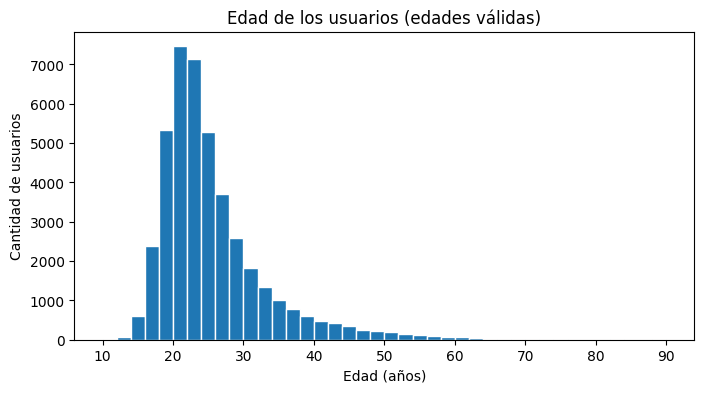

In [ ]:
# 4.1.a Edad: solo edades entre 10 y 90; las demás son faltantes 
edades = q("SELECT age FROM users WHERE age BETWEEN 10 AND 90")
print(edades["age"].describe())

plt.figure(figsize=(8, 4))
plt.hist(edades["age"], bins=range(10, 92, 2), edgecolor="white")
plt.title("Edad de los usuarios (edades válidas)")
plt.xlabel("Edad (años)")
plt.ylabel("Cantidad de usuarios")
plt.show()

**Observación 4.1.a (edad):** la mitad de los usuarios con edad válida tiene entre 20 y 28 años y la mediana es 23.
La mayoría son jóvenes, no representan a toda la gente que escucha música.

,genero,usuarios,porcentaje
0,m,36506,66.1
1,f,13937,25.3
2,no informado,4747,8.6


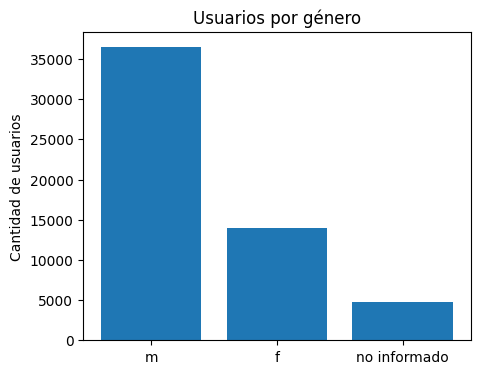

In [ ]:
# 4.1.b Género: agrupamos "n" y los vacíos como "no informado"
genero = q("""
    SELECT CASE WHEN gender IN ('m', 'f') THEN gender ELSE 'no informado' END AS genero,
           COUNT(*) AS usuarios
    FROM users
    GROUP BY genero
    ORDER BY usuarios DESC
""")
genero["porcentaje"] = (genero["usuarios"] / genero["usuarios"].sum() * 100).round(1)
display(genero)

plt.figure(figsize=(5, 4))
plt.bar(genero["genero"], genero["usuarios"])
plt.title("Usuarios por género")
plt.ylabel("Cantidad de usuarios")
plt.show()

**Observación 4.1.b (género):** el 66% de los usuarios son hombres, el 25% mujeres y el 8,6% no informó
su género. La muestra está bastante sesgada hacia los hombres.

Cantidad de países: 208
Los 10 países con más usuarios suman el 68.7 % de los usuarios
Países con menos de 50 usuarios: 152


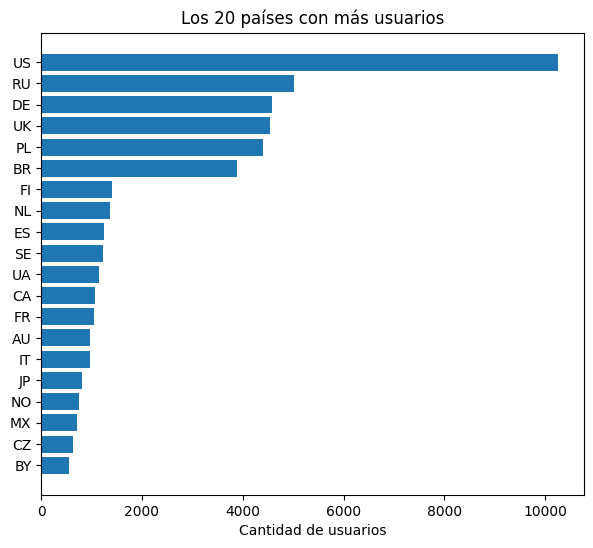

In [26]:
# 4.1.c País
paises = q("SELECT country, COUNT(*) AS usuarios FROM users GROUP BY country ORDER BY usuarios DESC")

# Porcentaje acumulado: qué parte del total suman los primeros países de la lista
paises["pct_acumulado"] = (paises["usuarios"].cumsum() / paises["usuarios"].sum() * 100).round(1)

print("Cantidad de países:", len(paises))
print("Los 10 países con más usuarios suman el", paises["pct_acumulado"].iloc[9], "% de los usuarios")
print("Países con menos de 50 usuarios:", (paises["usuarios"] < 50).sum())

# Los 20 primeros; iloc[::-1] invierte el orden para que el mayor quede arriba
top20 = paises.head(20).iloc[::-1]
plt.figure(figsize=(7, 6))
plt.barh(top20["country"], top20["usuarios"])
plt.title("Los 20 países con más usuarios")
plt.xlabel("Cantidad de usuarios")
plt.show()

**Observación 4.1.c (país):** los usuarios están muy concentrados. Los 10 países con más usuarios suman
el 68,7% del total, y 152 de los 208 países tienen menos de 50 usuarios. Argentina tiene 282.

La edad, el género y el país no los vamos a usar para armar los grupos del clustering

### 4.2 Escuchas

count     55143.000000
mean       6373.779682
std        9118.109300
min           1.000000
25%        1242.000000
50%        5028.000000
75%        8750.000000
max      345014.000000
Name: escuchas, dtype: float64


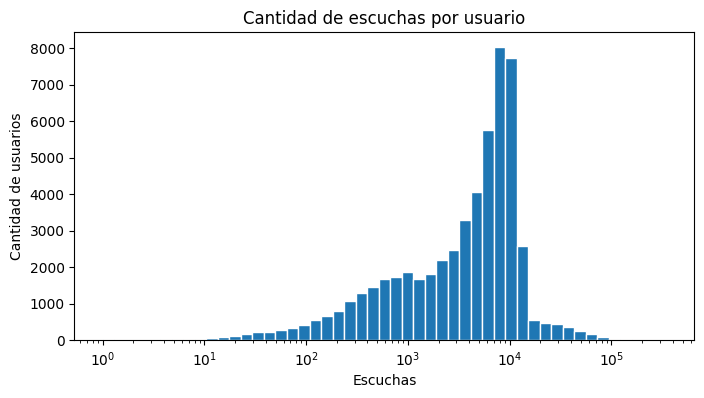

In [27]:
# 4.2.a Escuchas por usuario
por_usuario = q("SELECT user_id, COUNT(*) AS escuchas FROM events GROUP BY user_id")
print(por_usuario["escuchas"].describe())

# Los valores van de 1 a cientos de miles: con escala lineal todo queda amontonado a la izquierda.
# Usamos intervalos y eje en escala logarítmica para poder ver la distribución.
intervalos = np.logspace(0, np.log10(por_usuario["escuchas"].max()), 50)

plt.figure(figsize=(8, 4))
plt.hist(por_usuario["escuchas"], bins=intervalos, edgecolor="white")
plt.xscale("log")
plt.title("Cantidad de escuchas por usuario")
plt.xlabel("Escuchas")
plt.ylabel("Cantidad de usuarios")
plt.show()

**Observación 4.2.a (escuchas por usuario):** la mitad de los usuarios tiene menos de 5.028 escuchas y
el 75% menos de 8.750, pero el máximo es 345.014. Por eso usamos escala logarítmica: con la escala normal
casi todos los usuarios quedan amontonados en la primera barra. La mayoría está entre 1.000 y 10.000
escuchas, y arriba de 10.000 la cantidad de usuarios baja de golpe. 

Para el clustering vamos a describir a cada usuario con promedios de lo que escucha (energía, valencia,
etc.). Si alguien tiene muy pocas escuchas, esos promedios dependen de pocas canciones y no dicen mucho.


In [28]:
# Cuántos usuarios tienen al menos X escuchas, para elegir un mínimo para el clustering
total_usuarios = len(por_usuario)

for minimo in [10, 50, 100, 500, 1000]:
    quedan = (por_usuario["escuchas"] >= minimo).sum()
    print(f"Con {minimo:>5} escuchas o más: {quedan:,} usuarios ({quedan / total_usuarios * 100:.1f}%)")

Con    10 escuchas o más: 54,984 usuarios (99.7%)
Con    50 escuchas o más: 54,136 usuarios (98.2%)
Con   100 escuchas o más: 53,290 usuarios (96.6%)
Con   500 escuchas o más: 47,465 usuarios (86.1%)
Con  1000 escuchas o más: 42,822 usuarios (77.7%)


**Observación:** Elegimos trabajar con un mínimo de 100 escuchas por usuario. Con este filtro quedan 53.290 usuarios, es decir, el 96,6% de los usuarios con escuchas registradas. De esta manera, se eliminan muy pocos usuarios (3,4%) y evitamos calcular los promedios de las características musicales a partir de muy pocas escuchas, sin reducir demasiado el tamaño del dataset.


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,anio,escuchas,usuarios_activos,escuchas_por_usuario
0,2005,786963,606,1299.0
1,2006,2870944,1888,1521.0
2,2007,7111575,4282,1661.0
3,2008,12657501,7805,1622.0
4,2009,21707665,13242,1639.0
5,2010,34585255,20708,1670.0
6,2011,55158881,33163,1663.0
7,2012,90705031,50545,1795.0
8,2013,91813023,44816,2049.0
9,2014,34072494,34792,979.0


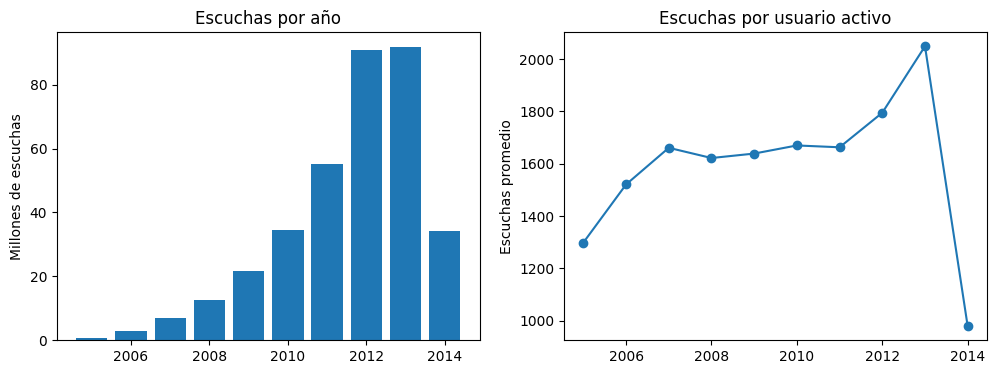

In [29]:
# 4.2.b Escuchas por año, y escuchas promedio por usuario activo en cada año
anual = q("""
    SELECT year(to_timestamp("timestamp")) AS anio,
           COUNT(*)                AS escuchas,
           COUNT(DISTINCT user_id) AS usuarios_activos
    FROM events
    WHERE "timestamp" >= 1104537600
    GROUP BY anio
    ORDER BY anio
""")
anual["escuchas_por_usuario"] = (anual["escuchas"] / anual["usuarios_activos"]).round()
display(anual)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].bar(anual["anio"], anual["escuchas"] / 1e6)
ejes[0].set_title("Escuchas por año")
ejes[0].set_ylabel("Millones de escuchas")
ejes[1].plot(anual["anio"], anual["escuchas_por_usuario"], marker="o")
ejes[1].set_title("Escuchas por usuario activo")
ejes[1].set_ylabel("Escuchas promedio")
plt.show()

**Observación 4.2.b (escuchas por año):**
- Las escuchas totales crecen mucho año a año, pero las escuchas por usuario activo se mantienen
  bastante parecidas (entre 1.500 y 1.700 por año), con una suba en 2012 y 2013.
- O sea que hasta 2012 el aumento total se podría explicar en buena parte porque hay más usuarios activos. En 2013 hay menos usuarios activos que en 2012, pero escuchan más en promedio.
- En 2014 bajan, pero no tenemos el año completo.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

El 1% de artistas más escuchados (3,378 artistas) suma el 69.2% de las escuchas
El 10% de artistas más escuchados (33,784 artistas) suma el 96.3% de las escuchas


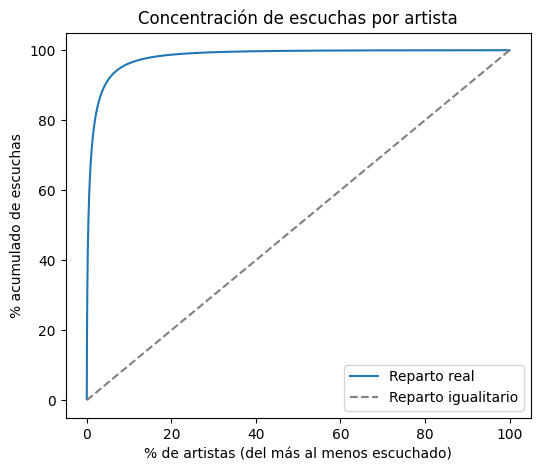

In [30]:
# 4.2.c Concentración de escuchas por artista
por_artista = q("SELECT artist_id, COUNT(*) AS escuchas FROM events GROUP BY artist_id ORDER BY escuchas DESC")

# Porcentaje acumulado de escuchas y de artistas, del más al menos escuchado
por_artista["pct_escuchas"] = por_artista["escuchas"].cumsum() / por_artista["escuchas"].sum() * 100
por_artista["pct_artistas"] = np.arange(1, len(por_artista) + 1) / len(por_artista) * 100

for p in [1, 10]:
    n = int(len(por_artista) * p / 100)
    print(f"El {p}% de artistas más escuchados ({n:,} artistas) suma el "
          f"{por_artista['pct_escuchas'].iloc[n - 1]:.1f}% de las escuchas")

plt.figure(figsize=(6, 5))
plt.plot(por_artista["pct_artistas"], por_artista["pct_escuchas"], label="Reparto real")
plt.plot([0, 100], [0, 100], linestyle="--", color="gray", label="Reparto igualitario")
plt.title("Concentración de escuchas por artista")
plt.xlabel("% de artistas (del más al menos escuchado)")
plt.ylabel("% acumulado de escuchas")
plt.legend()
plt.show()

**Observación 4.2.c (concentración por artista):** las escuchas están muy concentradas en pocos artistas.
El 1% de los artistas junta el 69,2% de las escuchas, y el 10% junta el 96,3%. La gran mayoría de los
artistas tiene muy pocas escuchas.
Si trabajamos solo con los artistas más escuchados, las tablas quedan mucho más chicas. Según cuántos artistas elijamos, también podemos perder una parte importante de las escuchas.

In [31]:
# Qué porcentaje de las escuchas juntan los N artistas más escuchados.
# por_artista ya está ordenado de mayor a menor, así que la fila N-1 tiene el acumulado de los primeros N.
for n in [1000, 10000]:
    print(f"Los {n:,} artistas más escuchados juntan el {por_artista['pct_escuchas'].iloc[n - 1]:.1f}% de las escuchas")

Los 1,000 artistas más escuchados juntan el 46.4% de las escuchas
Los 10,000 artistas más escuchados juntan el 85.9% de las escuchas


Los 1.000 artistas más escuchados concentran el 46,4% de las escuchas, mientras que los 10.000 primeros reúnen el 85,9%. Esto muestra que una parte importante de las escuchas se concentra en un grupo relativamente reducido de artistas. Para el recomendador vamos a ordenar por oyentes distintos, que no es lo mismo que ordenar por escuchas. Estos porcentajes son los del ranking por escuchas.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

count    55143.000000
mean       326.728107
std        365.265740
min          1.000000
25%        102.000000
50%        220.000000
75%        423.000000
max      13354.000000
Name: artistas, dtype: float64


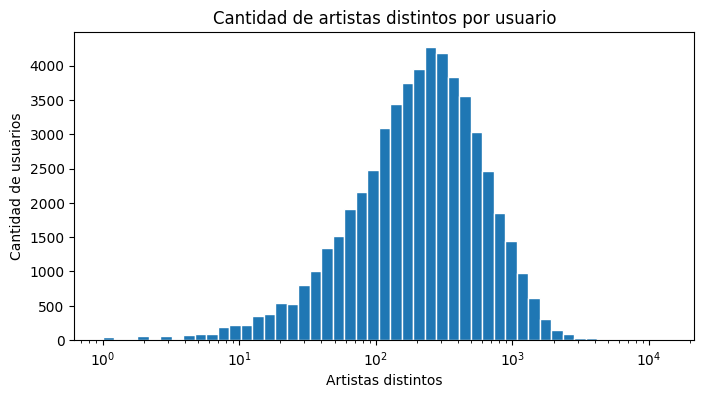

In [41]:
# 4.2.d Cuántos artistas distintos escucha cada usuario
artistas_usuario = q("""
    SELECT user_id, COUNT(DISTINCT artist_id) AS artistas
    FROM events
    GROUP BY user_id
""")
print(artistas_usuario["artistas"].describe())

# Igual que con las escuchas, los valores van de 1 a miles: usamos escala logarítmica
intervalos = np.logspace(0, np.log10(artistas_usuario["artistas"].max()), 50)

plt.figure(figsize=(8, 4))
plt.hist(artistas_usuario["artistas"], bins=intervalos, edgecolor="white")
plt.xscale("log")
plt.title("Cantidad de artistas distintos por usuario")
plt.xlabel("Artistas distintos")
plt.ylabel("Cantidad de usuarios")
plt.show()

**Observación 4.2.d (artistas por usuario):** La mediana es de 220 artistas por usuario, aunque hay usuarios que llegan a escuchar más de 13.000 artistas. Algunos escuchan muchos más artistas que otros, aunque también puede influir la cantidad total de escuchas de cada usuario.

**4.2.e Tiempo entre escuchas**

Calculamos cuánto tiempo pasa entre cada escucha y la anterior del mismo usuario. Para eso usamos
LAG, que trae el valor de la fila anterior (ordenando por fecha dentro de cada usuario). Como ordenar
351 millones de escuchas es muy pesado, lo hacemos con el 1% de los usuarios (los que tienen un
user_id divisible por 100). No es una muestra aleatoria.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Hasta   5 minutos: 51.4%
Hasta  15 minutos: 80.6%
Hasta  30 minutos: 86.7%
Hasta  60 minutos: 89.6%
Hasta 120 minutos: 91.5%


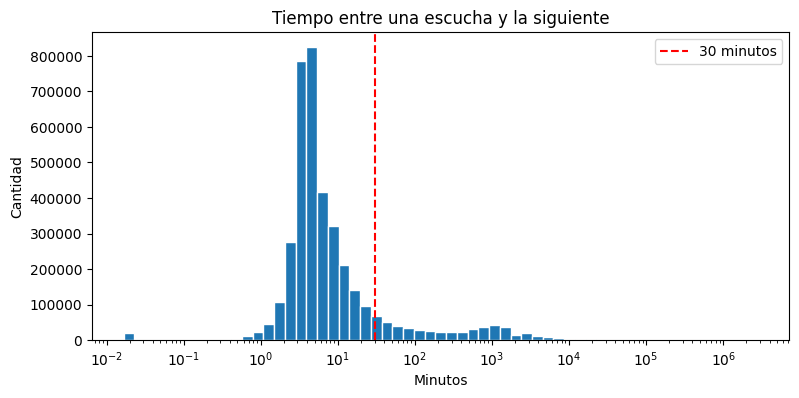

In [42]:
# Minutos entre cada escucha y la anterior del mismo usuario (muestra del 1% de los usuarios).
# La primera escucha de cada usuario no tiene anterior y queda en nulo, por eso el dropna().
gaps = q("""
    SELECT user_id,
           ("timestamp" - LAG("timestamp") OVER (PARTITION BY user_id ORDER BY "timestamp")) / 60.0 AS minutos
    FROM events
    WHERE user_id % 100 = 0
      AND "timestamp" >= 1104537600
""").dropna()

# Qué porcentaje de las veces la escucha siguiente llega antes de X minutos
for m in [5, 15, 30, 60, 120]:
    print(f"Hasta {m:>3} minutos: {(gaps['minutos'] <= m).mean() * 100:.1f}%")

# Histograma en escala logarítmica: los tiempos van de segundos a meses.
# Dejamos afuera los 0 porque el logaritmo de 0 no existe.
positivos = gaps.loc[gaps["minutos"] > 0, "minutos"]
intervalos = np.logspace(np.log10(positivos.min()), np.log10(positivos.max()), 60)

plt.figure(figsize=(9, 4))
plt.hist(positivos, bins=intervalos, edgecolor="white")
plt.xscale("log")
plt.axvline(30, color="red", linestyle="--", label="30 minutos")
plt.title("Tiempo entre una escucha y la siguiente")
plt.xlabel("Minutos")
plt.ylabel("Cantidad")
plt.legend()
plt.show()

In [34]:
# Cuántas sesiones saldrían con el corte de 30 minutos.
# Cada usuario arranca con una sesión, y cada vez que pasan más de 30 minutos empieza otra.
usuarios_muestra = gaps["user_id"].nunique()
sesiones = usuarios_muestra + (gaps["minutos"] > 30).sum()
escuchas_muestra = len(gaps) + usuarios_muestra   # se suma la primera escucha de cada usuario, que no tenía gap

print(f"Usuarios en la muestra:   {usuarios_muestra:,}")
print(f"Sesiones (corte 30 min):  {sesiones:,}")
print(f"Escuchas por sesión (promedio): {escuchas_muestra / sesiones:.1f}")

Usuarios en la muestra:   549
Sesiones (corte 30 min):  510,782
Escuchas por sesión (promedio): 7.5


**Observación 4.2.e (tiempo entre escuchas):** la mayoría de las escuchas se realizan con pocos minutos de diferencia. En la muestra, el 51,4% ocurre dentro de los 5 minutos y el 86,7% dentro de los 30 minutos. Podemos tomar los 30 minutos como límite de referencia si más adelante queremos separar las sesiones.

### 4.3 Audio features

,danceability,energy,valence,acousticness,instrumentalness,speechiness,liveness,loudness,tempo
count,200000.000,200000.000,199936.000,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000
mean,0.518,0.612,0.458,0.321,0.272,0.085,0.207,-9.685,121.408
std,0.182,0.271,0.267,0.355,0.368,0.113,0.181,5.331,29.463
min,0.050,0.000,0.000,0.000,0.000,0.022,0.002,-56.396,30.168
25%,0.390,0.407,0.230,0.006,0.000,0.035,0.097,-12.103,98.866
50%,0.528,0.653,0.443,0.141,0.008,0.047,0.130,-8.421,120.448
75%,0.653,0.851,0.673,0.651,0.673,0.080,0.269,-5.942,139.818
max,0.999,1.000,1.000,0.996,1.000,0.966,1.000,5.276,247.999


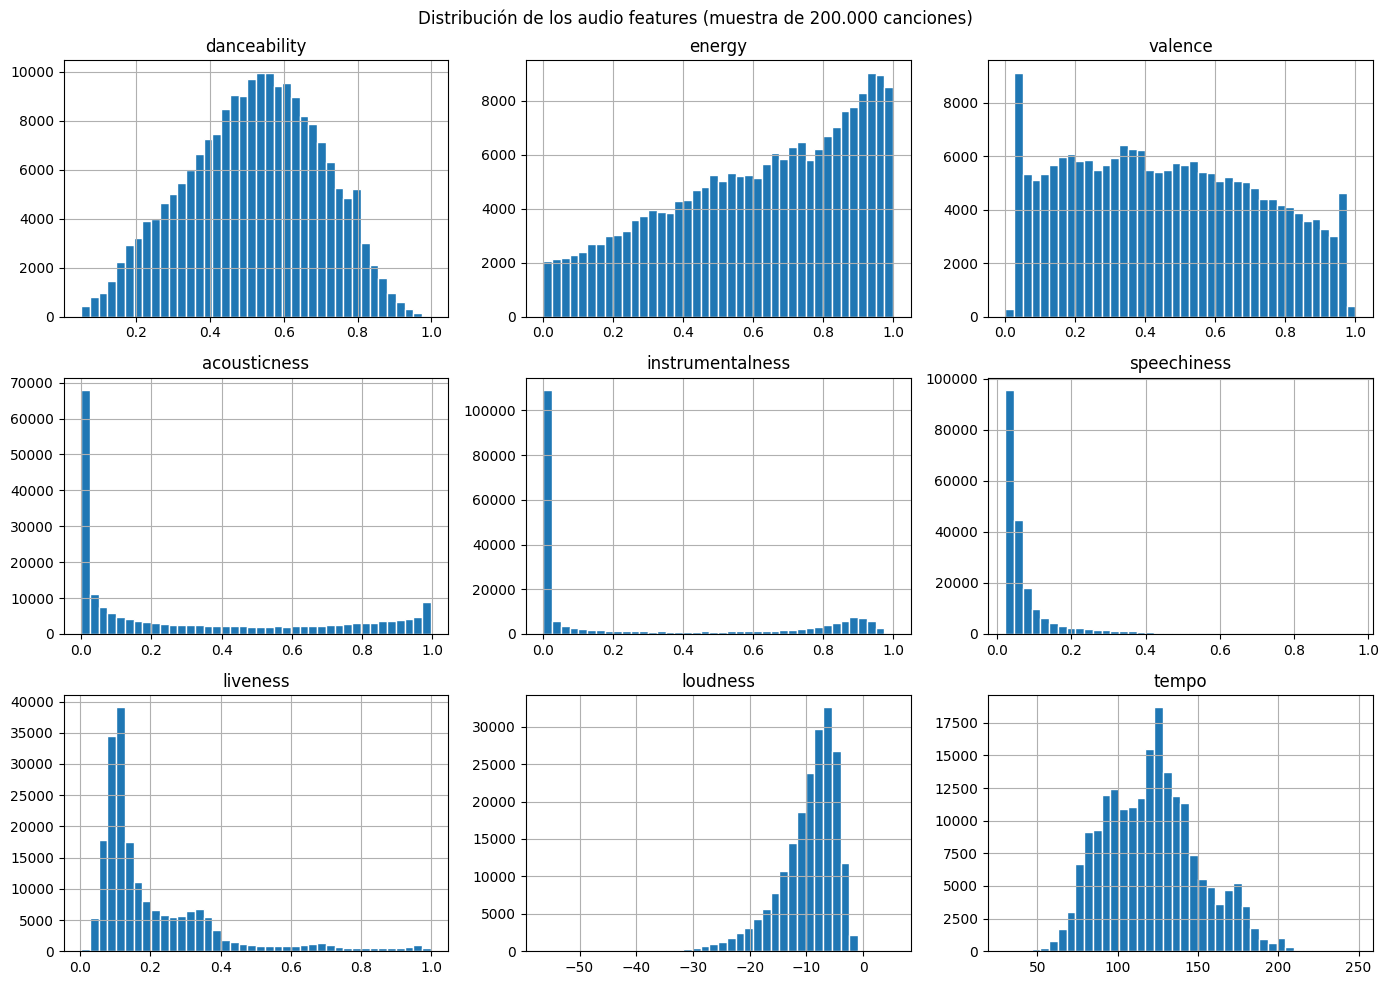

In [35]:
# 4.3.a Distribución de cada audio feature (sin tempo 0 ni loudness -60)
# La muestra puede cambiar al ejecutar de nuevo la consulta.
features = ["danceability", "energy", "valence", "acousticness", "instrumentalness",
            "speechiness", "liveness", "loudness", "tempo"]

muestra = q(f"""
    SELECT * FROM (
        SELECT {', '.join(features)}
        FROM acoustic_features
        WHERE tempo > 0 AND loudness > -60
    ) USING SAMPLE 200000 ROWS
""")

display(muestra.describe().round(3))

muestra.hist(bins=40, figsize=(14, 10), edgecolor="white")
plt.suptitle("Distribución de los audio features (muestra de 200.000 canciones)")
plt.tight_layout()
plt.show()

**Observación 4.3.a (distribuciones):**
- **danceability:** la mayoría de las canciones está alrededor de 0,5, con una forma parecida a una campana.
- **energy:** predominan los valores altos (la mediana es 0,65).
- **valence:** está bastante repartida en toda la escala, aunque hay algunos picos raros cerca de 0 y de 1.
- **acousticness:** hay muchas canciones con valores cerca de 0 y también otro grupo con valores altos.
- **instrumentalness:** pasa algo parecido, la mayoría cerca de 0 (tienen voz) y un grupo más chico con
  valores altos (instrumentales).
- **speechiness:** casi todo está por debajo de 0,1, varía muy poco.
- **liveness:** la mayoría tiene valores bajos, alrededor de 0,1. También varía poco.
- **loudness:** La mayoría de los valores se concentra entre -10 y -3 dB, y el pico más alto está cerca de -5 dB. Hacia la izquierda, las barras van disminuyendo hasta casi desaparecer, formando una cola larga. 
- **tempo:** La mayor concentración de valores está cerca de 120. También se observan algunas barras más bajas separadas del pico principal.

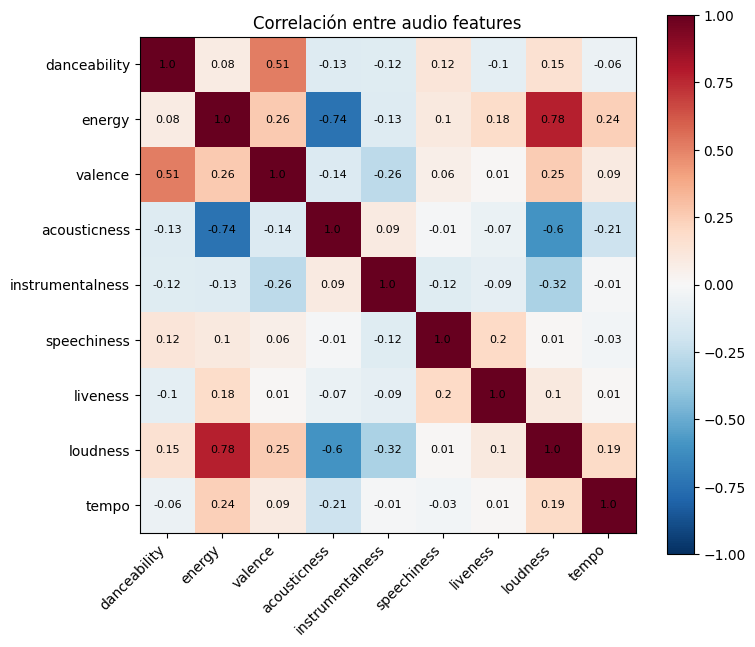

In [36]:
# 4.3.b Correlación entre audio features
corr = muestra.corr().round(2)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features)
for i in range(len(features)):
    for j in range(len(features)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(im)
plt.title("Correlación entre audio features")
plt.show()

**Observación 4.3.b (correlación):**
- energy y loudness: 0,78. Las canciones enérgicas suelen ser más fuertes.
- energy y acousticness: -0,74. Las acústicas suelen ser más tranquilas.
- acousticness y loudness: -0,60.
- danceability y valence: 0,51. Lo bailable suele sonar más alegre.



### 4.4 Qué nos llevamos para los modelos

**Clustering de usuarios**
- Vamos a describir a cada usuario con el promedio de lo que escucha: danceability, energy, valence,
  acousticness, instrumentalness y tempo. Además, cuántos artistas distintos escucha y qué tan variado es
  lo que escucha.
- Por ahora dejamos afuera loudness por su correlación con energy, y speechiness y liveness porque la mayoría de los valores son bajos. Vamos a revisar las variables a nivel de usuario antes de decidir cuáles usar en el modelo.
- Solo usuarios con al menos 100 escuchas, para evitar perfiles basados en pocas escuchas (4.2.a).
- Las variables están en escalas muy distintas (el tempo ronda 120 y varias características de audio van de 0 a 1), así que
  antes de K-means hay que estandarizarlas.
- La edad, el género y el país no entran al modelo: los usamos después para describir los grupos.

**Sistema de recomendación**
- Las escuchas están muy concentradas (4.2.c), así que proponemos trabajar con los 10.000 artistas con más oyentes distintos.
- La tabla usuario × artista va a estar casi vacía (cada usuario escucha una parte muy chica de los
  artistas), así que hay que guardarla como matriz dispersa.
- Como hay usuarios que escuchan a un artista miles de veces, vamos a probar el logaritmo de las escuchas. Para evaluar el modelo con una separación temporal, la selección de usuarios y artistas se hará usando solamente las escuchas de entrenamiento.

**A tener en cuenta en las conclusiones**
- Los usuarios son sobre todo jóvenes, hombres y de pocos países (4.1), así que los resultados hablan
  de los usuarios de Last.fm y no de todos los que escuchan música.
- Los datos son de 2005–2014 y solo incluyen un subconjunto de los artistas del LFM-1b (2.5).